# Signal vs background topology

Toy recreation of the HPXe track-topology plot: a $0\nu\beta\beta$ signal (two electrons from a common vertex, a Bragg blob at each end) vs a single-electron background (only one blob).

Track shapes are traced from the reference figure (waypoints read off by eye), with a small random wiggle. The $Q_{\beta\beta}$ energy is shared between the track body and ~400 keV blobs, smeared by diffusion and voxelised in 1 mm$^2$ voxels, so the colour scale is energy per voxel in keV (track $\sim$1.5 keV, blobs $\sim$6 keV). Each track is centred in its own square window; both windows have the same size. Drawn with `RdBu_r` and LaTeX (Computer Modern) fonts.

In [5]:
import shutil
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
from scipy.ndimage      import gaussian_filter, gaussian_filter1d
from scipy.interpolate  import splprep, splev

# Real LaTeX needs both latex and dvipng; otherwise fall back to matplotlib's Computer Modern mathtext
USE_TEX = shutil.which('latex') is not None and shutil.which('dvipng') is not None

plt.rcParams.update({
    'text.usetex'                : USE_TEX,
    'font.family'                : 'serif',
    'font.serif'                 : ['Computer Modern Roman', 'cmr10'],
    'mathtext.fontset'           : 'cm',
    'axes.formatter.use_mathtext': True,
    'axes.unicode_minus'         : False,
    'font.size'                  : 18,
    'axes.labelsize'             : 22,
    'xtick.labelsize'            : 18,
    'ytick.labelsize'            : 18,
    'xtick.major.size'           : 8,
    'ytick.major.size'           : 8,
    'xtick.major.width'          : 1.2,
    'ytick.major.width'          : 1.2,
    'xtick.direction'            : 'out',
    'ytick.direction'            : 'out',
    'xtick.top'                  : False,
    'ytick.right'                : False,
    'xtick.minor.visible'        : False,
    'ytick.minor.visible'        : False,
})
print('usetex:', USE_TEX)

usetex: False


## Track shapes and energy deposition

In [6]:
QBB    = 2458.   # 136Xe Q-value (keV)
E_BLOB = 400.    # energy in each end-of-track blob (keV)
VOXEL  = 2.0     # voxel size (mm): coarse, so the pixels show like in a real reconstruction
SIGMA  = 2.0     # diffusion smearing (mm)
STEP   = 0.5     # sampling step along the track (mm)

# (x, y) waypoints in mm read off the reference figure, from one end of the track to the other
SIGNAL_PATH = np.array([( 24,  24), ( 25,  18), ( 26,  12), ( 22,   7), ( 15,   5), (  8,   3),
                        (  4,   0), (  1,  -5), ( -4,  -8), ( -9,  -8), ( -9, -12), ( -5, -10),
                        (  0,  -8), (  6,  -8), ( 10,  -9), ( 10, -16), (  9, -22), (  5, -26),
                        (  3, -32), (  1, -38), ( -4, -42), (-10, -43), (-16, -46), (-20, -50),
                        (-24, -46), (-24, -41)], float)

BACKGROUND_PATH = np.array([( 41, -29), ( 45, -33), ( 50, -38), ( 55, -42), ( 60, -45), ( 64, -48),
                            ( 68, -53), ( 72, -57), ( 80, -57), ( 88, -60), ( 95, -64), (102, -66),
                            (108, -66), (115, -63), (122, -58), (130, -54), (136, -52), (140, -50),
                            (142, -45), (143, -35), (145, -25), (148, -18), (151, -17)], float)

# Smooth spline through the waypoints, resampled every `step` mm, plus a correlated random wiggle
def trace(waypoints, rng, wiggle=2.0, corr=3.0, step=STEP):
    tck, _ = splprep(waypoints.T, s=0)
    pts    = np.array(splev(np.linspace(0, 1, 4000), tck)).T
    s      = np.concatenate([[0], np.cumsum(np.linalg.norm(np.diff(pts, axis=0), axis=1))])
    s_new  = np.arange(0, s[-1], step)
    xy     = np.column_stack([np.interp(s_new, s, pts[:, 0]), np.interp(s_new, s, pts[:, 1])])
    noise  = gaussian_filter1d(rng.normal(size=xy.shape), corr / step, axis=0)
    return xy + wiggle * noise / noise.std()

# Slowly varying random profile along the track, between lo and hi (corr = correlation length in mm)
def lumps(n, rng, corr, lo, hi, step=STEP):
    x = gaussian_filter1d(rng.normal(size=n), corr / step)
    return lo + (hi - lo) * (x - x.min()) / np.ptp(x)

# Energy deposits along the path; blob_ends says which of the two ends has a Bragg blob
def make_event(waypoints, blob_ends, rng, E=QBB, E_blob=E_BLOB, blob_sigma=2.5,
               n_spots=4, E_spot=12., spot_sigma=2.):
    xy   = trace(waypoints, rng)
    ends = [xy[0], xy[-1]]
    hits, edep = [], []

    for p, has_blob in zip(ends, blob_ends):
        if has_blob:
            # elongated blob with a random orientation
            phi = rng.uniform(0, np.pi)
            rot = np.array([[np.cos(phi), -np.sin(phi)], [np.sin(phi), np.cos(phi)]])
            hits.append(p + rng.normal(0, 1, (400, 2)) * blob_sigma * np.array([1.4, 0.7]) @ rot)
            edep.append(np.full(400, E_blob / 400))

    # a few small dense spots along the track (delta electrons, fluctuations)
    for i in rng.integers(0, len(xy), n_spots):
        hits.append(xy[i] + rng.normal(0, spot_sigma, (50, 2)))
        edep.append(np.full(50, E_spot / 50))

    # the rest of the energy goes into the track body: lumpy along the track and of uneven width
    w     = rng.gamma(3, size=len(xy)) * lumps(len(xy), rng, 6, 0.6, 1.4)
    width = lumps(len(xy), rng, 8, 1.0, 3.0)
    w    *= (E - sum(e.sum() for e in edep)) / w.sum()
    n     = 10   # points per step, spread across the track
    hits.append(np.repeat(xy, n, axis=0) + rng.normal(0, 1, (n * len(xy), 2)) * np.repeat(width, n)[:, None])
    edep.append(np.repeat(w / n, n))
    return np.vstack(hits), np.concatenate(edep), list(zip(ends, blob_ends))

## Plotting

In [7]:
CMAP     = plt.get_cmap('RdBu_r')
VMAX     = 6.5           # keV/mm^2, top of the colour scale
THRESH   = 0.3           # keV/mm^2, voxels below this are zeroed (blocky track edge, like a reconstruction)
RING_OK  = CMAP(0.70)    # salmon from RdBu_r: end with a blob
RING_BAD = CMAP(0.30)    # light blue from RdBu_r: end without a blob

# Square window of half-width `half` centred on the track's bounding box
def centred_window(hits, half):
    c = (hits.min(0) + hits.max(0)) / 2
    return (c[0] - half, c[0] + half), (c[1] - half, c[1] + half)

# Voxelised energy density (keV/mm^2) smeared by diffusion over the plotting window
def make_image(hits, edep, xlim, ylim, voxel=VOXEL, sigma=SIGMA):
    ex = np.arange(xlim[0], xlim[1] + voxel, voxel)
    ey = np.arange(ylim[0], ylim[1] + voxel, voxel)
    img, _, _ = np.histogram2d(hits[:, 0], hits[:, 1], bins=[ex, ey], weights=edep)
    img = gaussian_filter(img, sigma / voxel).T / voxel**2
    img[img < THRESH] = 0
    return img, ex, ey

# Hand-drawn check (good) or cross (bad) in data coordinates, independent of the font
def draw_mark(ax, xy, good, s):
    x, y = xy
    kw   = dict(color=RING_OK if good else RING_BAD, lw=3,
                solid_capstyle='round', solid_joinstyle='round', clip_on=False)
    if good:
        ax.plot([x - s, x - s/3, x + s], [y, y - 0.8*s, y + s], **kw)
    else:
        ax.plot([x - 0.7*s, x + 0.7*s], [y - 0.7*s, y + 0.7*s], **kw)
        ax.plot([x - 0.7*s, x + 0.7*s], [y + 0.7*s, y - 0.7*s], **kw)

# marks: per-end (dx, dy) offset in mm of the check/cross from the track end; None = pointing away from the track
def plot_event(ax, hits, edep, ends, label, xlim, ylim, R=10, marks=(None, None), ylabel='Y (mm)'):
    img, ex, ey = make_image(hits, edep, xlim, ylim)
    im = ax.imshow(img, origin='lower', extent=(ex[0], ex[-1], ey[0], ey[-1]),
                   cmap=CMAP, vmin=0, vmax=VMAX, interpolation='nearest')

    centre = hits[:, :2].mean(0)
    for (p, good), offset in zip(ends, marks):
        if offset is None:
            offset = 1.7*R * (p - centre) / np.linalg.norm(p - centre)
        ax.add_patch(Circle(p, R, fill=False, ec=RING_OK if good else RING_BAD, lw=2.5))
        draw_mark(ax, p + np.asarray(offset), good, s=4)

    ax.text(0.05, 0.96, label, transform=ax.transAxes, va='top', color='w', fontsize=34)
    ax.set(xlim=xlim, ylim=ylim, xlabel='X (mm)', ylabel=ylabel)
    print(f'{label:<10}: E = {img.sum() * VOXEL**2:.0f} keV, max = {img.max():.2f} keV/mm^2')
    return im

signal    : E = 2326 keV, max = 6.48 keV/mm^2
background: E = 2310 keV, max = 5.99 keV/mm^2


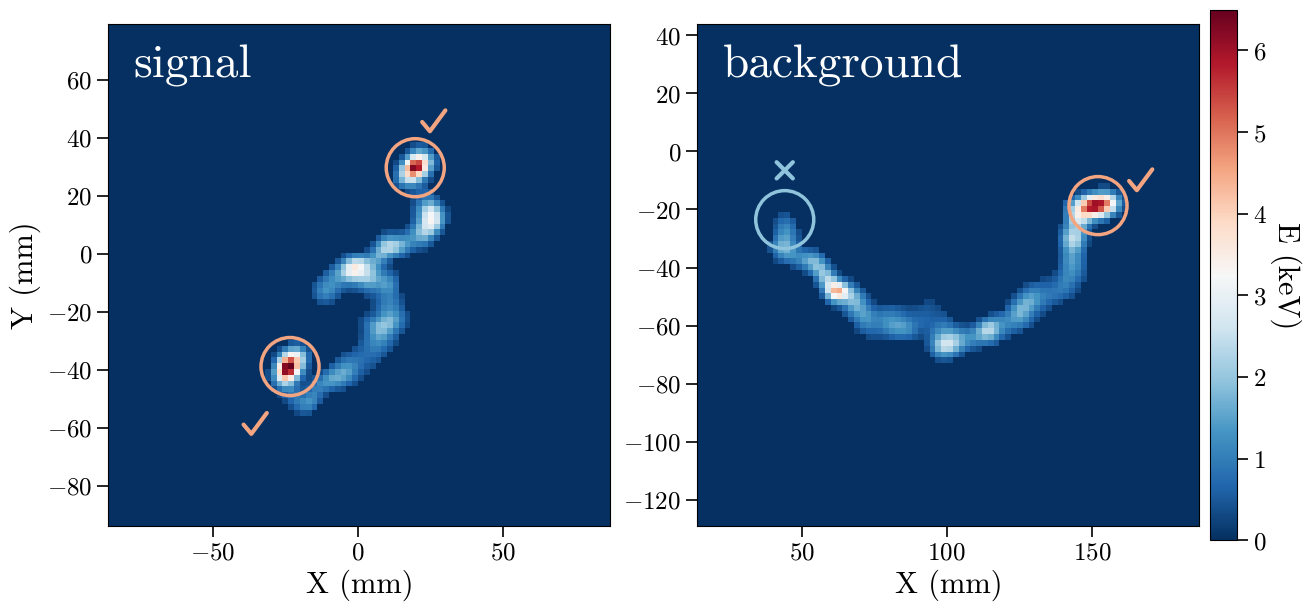

In [8]:
rng = np.random.default_rng(1234)   # change the seed for a different wiggle
sig = make_event(SIGNAL_PATH,     (True,  True), rng)
bkg = make_event(BACKGROUND_PATH, (False, True), rng)

# Same window size for both panels (same mm scale), each centred on its own track
MARGIN = 25   # mm around the larger track
half   = max(np.ptp(ev[0], axis=0).max() for ev in (sig, bkg)) / 2 + MARGIN

fig, axes = plt.subplots(1, 2, figsize=(13, 6), layout='constrained')
plot_event(axes[0], *sig, 'signal',     *centred_window(sig[0], half),
           marks=(None, (-12, -20)))              # lower blob: check a bit lower
im = plot_event(axes[1], *bkg, 'background', *centred_window(bkg[0], half),
                marks=((0, 17), None), ylabel='')  # cross on top of the circle
cbar = fig.colorbar(im, ax=axes, pad=0.01)
cbar.set_label('E (keV)', rotation=270, labelpad=25)
cbar.ax.minorticks_off()
fig.savefig('NEXTTopology.png', bbox_inches='tight')
plt.show()

## NEXT TPC schematic

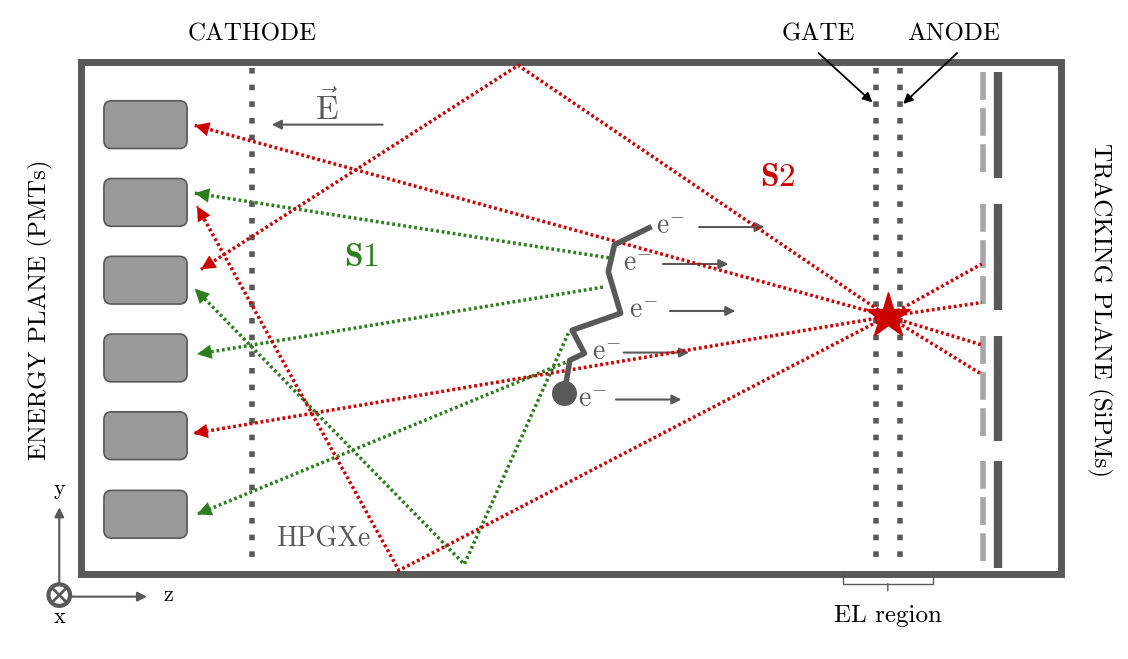

In [10]:
from matplotlib.patches import FancyBboxPatch, Rectangle

# All coordinates are the pixel positions of the reference image (y pointing down)
GREY, LIGHT = '0.35', '0.65'
RED, GREEN  = '#cc0000', '#2e7d1f'
DENSE_DOTS  = (0, (0.8, 0.8))   # dot and gap lengths in line widths: lower the gap for denser dots
GRID_DOTS   = (0, (1, 2))

fig, ax = plt.subplots(figsize=(14.4, 8.3))
ax.set(xlim=(0, 1440), ylim=(830, 0), aspect='equal')
ax.axis('off')

def label(x, y, text, **kw):
    ax.text(x, y, text, ha='center', va='center', **{'fontsize': 18, **kw})

# Thin arrow, e.g. for the drifting electrons
def arrow(start, end, color=GREY, lw=1.5):
    ax.annotate('', xy=end, xytext=start,
                arrowprops=dict(arrowstyle='-|>', color=color, lw=lw, shrinkA=0, shrinkB=0, mutation_scale=14))

# Dotted light ray through the given points, with a solid arrowhead at the last one
def ray(points, color):
    points = np.array(points, float)
    ax.plot(*points.T, color=color, lw=2.5, ls=DENSE_DOTS, zorder=3)
    tail = points[-1] - points[-2]
    ax.annotate('', xy=points[-1], xytext=points[-1] - 25 * tail / np.linalg.norm(tail), zorder=4,
                arrowprops=dict(arrowstyle='-|>', color=color, lw=0, shrinkA=0, shrinkB=0, mutation_scale=26))

# Vessel and PMTs
ax.add_patch(Rectangle((92, 68), 1273, 665, fill=False, ec=GREY, lw=5))
for y in (118, 219, 320, 421, 522, 624):
    ax.add_patch(FancyBboxPatch((126, y + 4), 100, 54, boxstyle='round,pad=4,rounding_size=10',
                                fc='0.6', ec=GREY, lw=1.2))

# Cathode, gate and anode meshes
for x in (314, 1125, 1156):
    ax.plot([x, x], [76, 722], color=GREY, lw=4, ls=GRID_DOTS)

# Tracking plane: front mesh (dashed) and SiPM boards
for y0, y1 in ((80, 218), (252, 390), (423, 560), (586, 725)):
    ax.plot([1264, 1264], [y0, y1], color=LIGHT, lw=4, ls=(0, (5, 1.5)))
    ax.plot([1283, 1283], [y0, y1], color=GREY, lw=6, solid_capstyle='butt')

# Ionisation track and drifting electrons
track = np.array([(830, 283), (785, 305), (777, 340), (793, 394), (730, 416), (746, 446), (727, 455), (720, 497)])
ax.plot(*track.T, color=GREY, lw=4, solid_joinstyle='round', zorder=5)
ax.plot(720, 497, 'o', color=GREY, markersize=17, zorder=5)
for x, y, x0, x1 in ((858, 282, 895, 980), (815, 330, 848, 933), (823, 391, 857, 942),
                     (775, 445, 797, 882), (757, 506, 787, 872)):
    label(x, y, r'e$^{-}$', color=GREY, fontsize=20)
    arrow((x0, y), (x1, y))

# S1: primary scintillation, from the track to the energy plane (one ray bounces off the bottom wall)
ray([(778, 322), (240, 238)], GREEN)
ray([(770, 360), (243, 447)], GREEN)
ray([(728, 455), (243, 655)], GREEN)
ray([(725, 420), (590, 720), (240, 362)], GREEN)

# S2: electroluminescence at the star, to the energy plane (two rays bounce off the walls) and tracking plane
star = (1140, 398)
ray([star, (240, 150)], RED)
ray([star, (238, 550)], RED)
ray([star, (660, 72), (248, 337)], RED)
ray([star, (505, 728), (243, 255)], RED)
for end in ((1262, 330), (1262, 380), (1262, 435), (1260, 472)):
    ax.plot(*np.array([star, end]).T, color=RED, lw=2.5, ls=DENSE_DOTS, zorder=3)
ax.plot(*star, '*', color=RED, markersize=34, zorder=6)

# Labels
label(314, 32, 'CATHODE')
label(1050, 32, 'GATE')
label(1226, 32, 'ANODE')
arrow((1050, 56), (1120, 120), color='k', lw=1.3)
arrow((1230, 56), (1160, 122), color='k', lw=1.3)
label(40, 389, 'ENERGY PLANE (PMTs)', rotation=90)
label(1415, 389, 'TRACKING PLANE (SiPMs)', rotation=270)
label(456, 321, r'$\mathbf{S1}$', color=GREEN, fontsize=24)
label(997, 218, r'$\mathbf{S2}$', color=RED, fontsize=24)
label(407, 687, 'HPGXe', color=GREY, fontsize=20)
ax.annotate('EL region', xy=(1140, 745), xytext=(1140, 787), ha='center', va='center', fontsize=18,
            arrowprops=dict(arrowstyle='-[, widthB=1.8, lengthB=0.5', color=GREY, lw=1, shrinkA=8, shrinkB=0))

# Electric field
arrow((484, 149), (340, 149))
label(412, 126, r'$\vec{\mathrm{E}}$', color=GREY, fontsize=24)

# Axes: x points into the page
arrow((64, 745), (64, 646))
arrow((78, 762), (178, 762))
ax.add_patch(Circle((64, 760), 14, fill=False, ec=GREY, lw=3))
ax.plot([54, 74], [750, 770], color=GREY, lw=2)
ax.plot([54, 74], [770, 750], color=GREY, lw=2)
label(64, 622, 'y', fontsize=16)
label(205, 760, 'z', fontsize=16)
label(64, 788, 'x', fontsize=16)

fig.savefig('NEXT_TPC.png', bbox_inches='tight', dpi=200)
plt.show()